# METALYX — Notebook 2: SimCLR + B-spline Feature Fusion

**Purpose:** Compare three feature pipelines on the same official NEU-DET split:
1. **SimCLR-only:** ResNet-18 encoder embeddings.
2. **B-spline-only:** saved geometric features from Notebook 1.
3. **Fusion:** concatenated SimCLR and B-spline features.

This notebook does **not** train SimCLR. It loads an existing checkpoint, extracts embeddings, aligns them with the B-spline features by image path, fits the same downstream classifier settings for all three methods, and reports comparable metrics.

> **Checkpoint provenance matters:** the checkpoint must be the encoder weights produced by your intended SimCLR training run. If its origin is uncertain, record that limitation in the project report.

## 1. Install/import dependencies

In [19]:
# If running in Google Colab and a package is missing, uncomment:
# %pip install torch torchvision scikit-learn tqdm seaborn

from pathlib import Path
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", DEVICE)
print("PyTorch:", torch.__version__)

Device: cpu
PyTorch: 2.11.0+cpu


## 2. Mount Drive and configure paths

In [30]:

from pathlib import Path

ROOT = Path('/content/drive/MyDrive/METALYX')

print("=== B-spline feature files ===")
for p in ROOT.rglob('bspline_features.npz'):
    print(p)

print("\n=== SimCLR checkpoint files ===")
for p in ROOT.rglob('*.pth'):
    print(p)

print("\n=== Other model/checkpoint files ===")
for pattern in ('*.pt', '*.ckpt'):
    for p in ROOT.rglob(pattern):
        print(p)


=== B-spline feature files ===
/content/drive/MyDrive/METALYX/features/bspline_features.npz

=== SimCLR checkpoint files ===
/content/drive/MyDrive/METALYX/models/simclr_resnet18.pth

=== Other model/checkpoint files ===


In [20]:
from google.colab import drive
drive.mount('/content/drive')

DATA_ROOT = Path('/content/drive/MyDrive/NEU-DET')
TRAIN_IMAGE_DIR = DATA_ROOT / 'train' / 'images'
VAL_IMAGE_DIR = DATA_ROOT / 'validation' / 'images'

CHECKPOINT_PATH = Path('/content/drive/MyDrive/METALYX/models/simclr_resnet18.pth')
BSPLINE_FEATURE_FILE = Path('/content/drive/MyDrive/METALYX/features/bspline_features.npz')
OUTPUT_DIR = Path('/content/drive/MyDrive/METALYX/integrated_results')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    'crazing',
    'inclusion',
    'patches',
    'pitted_surface',
    'rolled-in_scale',
    'scratches'
]
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

for label, path in {
    'Train image directory': TRAIN_IMAGE_DIR,
    'Validation image directory': VAL_IMAGE_DIR,
    'SimCLR checkpoint': CHECKPOINT_PATH,
    'B-spline features': BSPLINE_FEATURE_FILE
}.items():
    print(f'{label}: {path} | exists={path.exists()}')

if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError("SimCLR checkpoint not found. Update CHECKPOINT_PATH.")
if not BSPLINE_FEATURE_FILE.exists():
    raise FileNotFoundError("B-spline feature file not found. Run Notebook 1 first.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Train image directory: /content/drive/MyDrive/NEU-DET/train/images | exists=True
Validation image directory: /content/drive/MyDrive/NEU-DET/validation/images | exists=True
SimCLR checkpoint: /content/drive/MyDrive/METALYX/models/simclr_resnet18.pth | exists=True
B-spline features: /content/drive/MyDrive/METALYX/features/bspline_features.npz | exists=True


## 3. Load saved B-spline features and verify their row metadata

In [21]:
with np.load(BSPLINE_FEATURE_FILE, allow_pickle=False) as data:
    X_train_bspline = data['X_train'].astype(np.float32)
    y_train_bspline = data['y_train'].astype(str)
    train_paths_bspline = data['train_paths'].astype(str)
    X_val_bspline = data['X_val'].astype(np.float32)
    y_val_bspline = data['y_val'].astype(str)
    val_paths_bspline = data['val_paths'].astype(str)
    bspline_feature_names = data['feature_names'].astype(str).tolist()

assert len(X_train_bspline) == len(y_train_bspline) == len(train_paths_bspline)
assert len(X_val_bspline) == len(y_val_bspline) == len(val_paths_bspline)
assert X_train_bspline.shape[1] == X_val_bspline.shape[1] == len(bspline_feature_names)
assert np.isfinite(X_train_bspline).all() and np.isfinite(X_val_bspline).all()

print("B-spline train:", X_train_bspline.shape)
print("B-spline validation:", X_val_bspline.shape)
print("Features:", bspline_feature_names)

B-spline train: (1440, 10)
B-spline validation: (360, 10)
Features: ['contour_count', 'total_length', 'largest_length', 'mean_length', 'total_area', 'mean_area', 'mean_abs_curvature', 'max_abs_curvature', 'curvature_std', 'mean_direction_change']


## 4. Index the official image splits and check alignment

In [22]:
def scan_class_folders(image_root, split_name):
    rows = []
    for class_name in CLASS_NAMES:
        class_dir = image_root / class_name
        if not class_dir.exists():
            raise FileNotFoundError(f"Missing class folder: {class_dir}")
        for path in sorted(class_dir.rglob('*')):
            if path.is_file() and path.suffix.lower() in IMAGE_EXTS:
                rows.append({
                    'image_path': str(path.resolve()),
                    'label': class_name,
                    'split': split_name
                })
    return pd.DataFrame(rows)

train_df = scan_class_folders(TRAIN_IMAGE_DIR, 'train')
val_df = scan_class_folders(VAL_IMAGE_DIR, 'validation')

def assert_same_paths_and_labels(frame, saved_paths, saved_labels, split_name):
    frame_paths = frame['image_path'].astype(str).to_numpy()
    frame_labels = frame['label'].astype(str).to_numpy()
    saved_paths = np.asarray(saved_paths).astype(str)
    saved_labels = np.asarray(saved_labels).astype(str)

    if len(set(saved_paths)) != len(saved_paths):
        raise ValueError(f"{split_name}: duplicate paths in saved B-spline metadata.")
    if set(frame_paths) != set(saved_paths):
        missing_saved = sorted(set(frame_paths) - set(saved_paths))[:5]
        extra_saved = sorted(set(saved_paths) - set(frame_paths))[:5]
        raise ValueError(
            f"{split_name}: image-path sets differ. "
            f"Missing from feature file (examples): {missing_saved}; "
            f"extra in feature file (examples): {extra_saved}. "
            "Re-run Notebook 1 against the same folders."
        )
    path_to_label = dict(zip(frame_paths, frame_labels))
    for path, label in zip(saved_paths, saved_labels):
        if path_to_label[path] != label:
            raise ValueError(f"{split_name}: label mismatch for {path}")
    print(f"{split_name}: path and label alignment verified ({len(saved_paths)} images).")

assert_same_paths_and_labels(train_df, train_paths_bspline, y_train_bspline, 'Train')
assert_same_paths_and_labels(val_df, val_paths_bspline, y_val_bspline, 'Validation')

# Reorder B-spline rows to match the canonical dataset index.
train_index = {path: i for i, path in enumerate(train_paths_bspline)}
val_index = {path: i for i, path in enumerate(val_paths_bspline)}
train_paths = train_df['image_path'].to_numpy()
val_paths = val_df['image_path'].to_numpy()
y_train = train_df['label'].to_numpy()
y_val = val_df['label'].to_numpy()

X_train_bspline = X_train_bspline[[train_index[p] for p in train_paths]]
X_val_bspline = X_val_bspline[[val_index[p] for p in val_paths]]

assert np.array_equal(y_train, y_train_bspline[[train_index[p] for p in train_paths]])
assert np.array_equal(y_val, y_val_bspline[[val_index[p] for p in val_paths]])
print("Canonical split sizes:", len(train_paths), len(val_paths))

Train: path and label alignment verified (1440 images).
Validation: path and label alignment verified (360 images).
Canonical split sizes: 1440 360


## 5. Build the ResNet-18 encoder and load checkpoint

In [23]:
# The expected SimCLR encoder is ResNet-18 with the final classification layer removed.
# Checkpoint loading handles common state-dict wrappers and projection-head keys.
def build_resnet18_encoder():
    try:
        model = models.resnet18(weights=None)
    except TypeError:  # compatibility with older torchvision
        model = models.resnet18(pretrained=False)
    model.fc = nn.Identity()
    return model

def load_state_dict_flexible(checkpoint_path, model):
    checkpoint = torch.load(checkpoint_path, map_location='cpu')
    if isinstance(checkpoint, dict):
        if 'state_dict' in checkpoint and isinstance(checkpoint['state_dict'], dict):
            state = checkpoint['state_dict']
        elif 'model_state_dict' in checkpoint and isinstance(checkpoint['model_state_dict'], dict):
            state = checkpoint['model_state_dict']
        elif 'encoder_state_dict' in checkpoint and isinstance(checkpoint['encoder_state_dict'], dict):
            state = checkpoint['encoder_state_dict']
        else:
            state = checkpoint
    else:
        raise TypeError("Checkpoint is not a state dictionary or a recognized checkpoint dictionary.")

    cleaned = {}
    for key, value in state.items():
        key = key.removeprefix('module.')
        # Common names from SimCLR implementations:
        if key.startswith('encoder.'):
            key = key[len('encoder.'):]
        if key.startswith('backbone.'):
            key = key[len('backbone.'):]
        # Ignore the projection head and any original classification head.
        if key.startswith(('projector.', 'projection_head.', 'projection.', 'fc.')):
            continue
        cleaned[key] = value

    result = model.load_state_dict(cleaned, strict=False)
    missing = list(result.missing_keys)
    unexpected = list(result.unexpected_keys)
    print("Missing keys:", missing[:20], ("..." if len(missing) > 20 else ""))
    print("Unexpected keys:", unexpected[:20], ("..." if len(unexpected) > 20 else ""))

    # A checkpoint that only partially loads is unsafe for this comparison.
    critical_missing = [k for k in missing if not k.startswith('fc.')]
    if critical_missing:
        raise RuntimeError(
            "Checkpoint did not fully load into the ResNet-18 encoder. "
            "Inspect key names and architecture before continuing."
        )
    return checkpoint

encoder = build_resnet18_encoder()
checkpoint_object = load_state_dict_flexible(CHECKPOINT_PATH, encoder)
encoder = encoder.to(DEVICE).eval()
print("Encoder output dimension: 512")

Missing keys: [] 
Unexpected keys: [] 
Encoder output dimension: 512


## 6. Extract embeddings from images

In [24]:
# Use deterministic preprocessing for all images. This should match the image
# normalization used by the original SimCLR training notebook.
IMAGE_SIZE = 224
BATCH_SIZE = 64
NUM_WORKERS = 2 if DEVICE.type == 'cuda' else 0

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])

class PathImageDataset(Dataset):
    def __init__(self, paths, transform):
        self.paths = list(paths)
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, idx):
        path = self.paths[idx]
        with Image.open(path) as image:
            image = image.convert('RGB')
            tensor = self.transform(image)
        return tensor, path

def extract_embeddings(paths, encoder, split_name):
    dataset = PathImageDataset(paths, eval_transform)
    loader = DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda')
    )
    features, returned_paths = [], []
    encoder.eval()
    with torch.no_grad():
        for images, batch_paths in tqdm(loader, desc=f'{split_name} embeddings'):
            images = images.to(DEVICE, non_blocking=True)
            output = encoder(images)
            if isinstance(output, (tuple, list)):
                output = output[0]
            features.append(output.detach().cpu().numpy().astype(np.float32))
            returned_paths.extend(list(batch_paths))
    matrix = np.concatenate(features, axis=0)
    returned_paths = np.asarray(returned_paths).astype(str)
    if not np.array_equal(returned_paths, np.asarray(paths).astype(str)):
        raise RuntimeError(f"{split_name}: embedding extraction changed path order.")
    if matrix.shape[1] != 512:
        raise ValueError(f"Expected 512-D embeddings, got {matrix.shape[1]}.")
    if not np.isfinite(matrix).all():
        raise ValueError(f"{split_name}: non-finite embedding values found.")
    return matrix

start = time.time()
X_train_simclr = extract_embeddings(train_paths, encoder, 'Train')
X_val_simclr = extract_embeddings(val_paths, encoder, 'Validation')
print("Train embeddings:", X_train_simclr.shape)
print("Validation embeddings:", X_val_simclr.shape)
print(f"Elapsed: {(time.time() - start) / 60:.1f} minutes")

Train embeddings:   0%|          | 0/23 [00:00<?, ?it/s]

Validation embeddings:   0%|          | 0/6 [00:00<?, ?it/s]

Train embeddings: (1440, 512)
Validation embeddings: (360, 512)
Elapsed: 3.8 minutes


## 7. Save SimCLR embeddings and verified alignment metadata

In [25]:
EMBEDDINGS_FILE = OUTPUT_DIR / 'simclr_embeddings.npz'
np.savez_compressed(
    EMBEDDINGS_FILE,
    X_train_simclr=X_train_simclr,
    X_val_simclr=X_val_simclr,
    y_train=y_train,
    y_val=y_val,
    train_paths=train_paths,
    val_paths=val_paths
)
print("Saved:", EMBEDDINGS_FILE)

Saved: /content/drive/MyDrive/METALYX/integrated_results/simclr_embeddings.npz


## 8. Train comparable classifiers: SimCLR, B-spline, and fusion

In [26]:
# Keep the classifier settings identical across all feature types.
CLASSIFIER_KWARGS = dict(
    max_iter=3000,
    class_weight='balanced',
    random_state=SEED
)

X_train_fusion = np.concatenate([X_train_simclr, X_train_bspline], axis=1)
X_val_fusion = np.concatenate([X_val_simclr, X_val_bspline], axis=1)

feature_sets = {
    'SimCLR-only': (X_train_simclr, X_val_simclr),
    'B-spline-only': (X_train_bspline, X_val_bspline),
    'Fusion': (X_train_fusion, X_val_fusion)
}

models_by_method = {}
predictions = {}
results = []

for method_name, (Xtr, Xva) in feature_sets.items():
    clf = make_pipeline(
        StandardScaler(),
        LogisticRegression(**CLASSIFIER_KWARGS)
    )
    clf.fit(Xtr, y_train)
    pred = clf.predict(Xva)
    models_by_method[method_name] = clf
    predictions[method_name] = pred
    results.append({
        'method': method_name,
        'train_samples': len(y_train),
        'validation_samples': len(y_val),
        'feature_dimensions': Xtr.shape[1],
        'accuracy': accuracy_score(y_val, pred),
        'macro_f1': f1_score(y_val, pred, average='macro'),
        'weighted_f1': f1_score(y_val, pred, average='weighted')
    })

results_df = pd.DataFrame(results).sort_values('method')
display(results_df)

,method,train_samples,validation_samples,feature_dimensions,accuracy,macro_f1,weighted_f1
1,B-spline-only,1440,360,10,0.738889,0.721016,0.721016
2,Fusion,1440,360,522,0.925000,0.924111,0.924111
0,SimCLR-only,1440,360,512,0.861111,0.859780,0.859780


## 9. Detailed classification report for each method

In [27]:
for method_name, pred in predictions.items():
    print('\n' + '=' * 72)
    print(method_name)
    print('=' * 72)
    print(classification_report(
        y_val, pred, labels=CLASS_NAMES, target_names=CLASS_NAMES,
        digits=4, zero_division=0
    ))


SimCLR-only
                 precision    recall  f1-score   support

        crazing     0.8548    0.8833    0.8689        60
      inclusion     0.8431    0.7167    0.7748        60
        patches     0.9375    1.0000    0.9677        60
 pitted_surface     0.7206    0.8167    0.7656        60
rolled-in_scale     0.8676    0.9833    0.9219        60
      scratches     0.9787    0.7667    0.8598        60

       accuracy                         0.8611       360
      macro avg     0.8671    0.8611    0.8598       360
   weighted avg     0.8671    0.8611    0.8598       360


B-spline-only
                 precision    recall  f1-score   support

        crazing     0.7125    0.9500    0.8143        60
      inclusion     0.8548    0.8833    0.8689        60
        patches     0.6964    0.6500    0.6724        60
 pitted_surface     0.4571    0.2667    0.3368        60
rolled-in_scale     0.7258    0.7500    0.7377        60
      scratches     0.8615    0.9333    0.8960        60

## 10. Confusion matrices

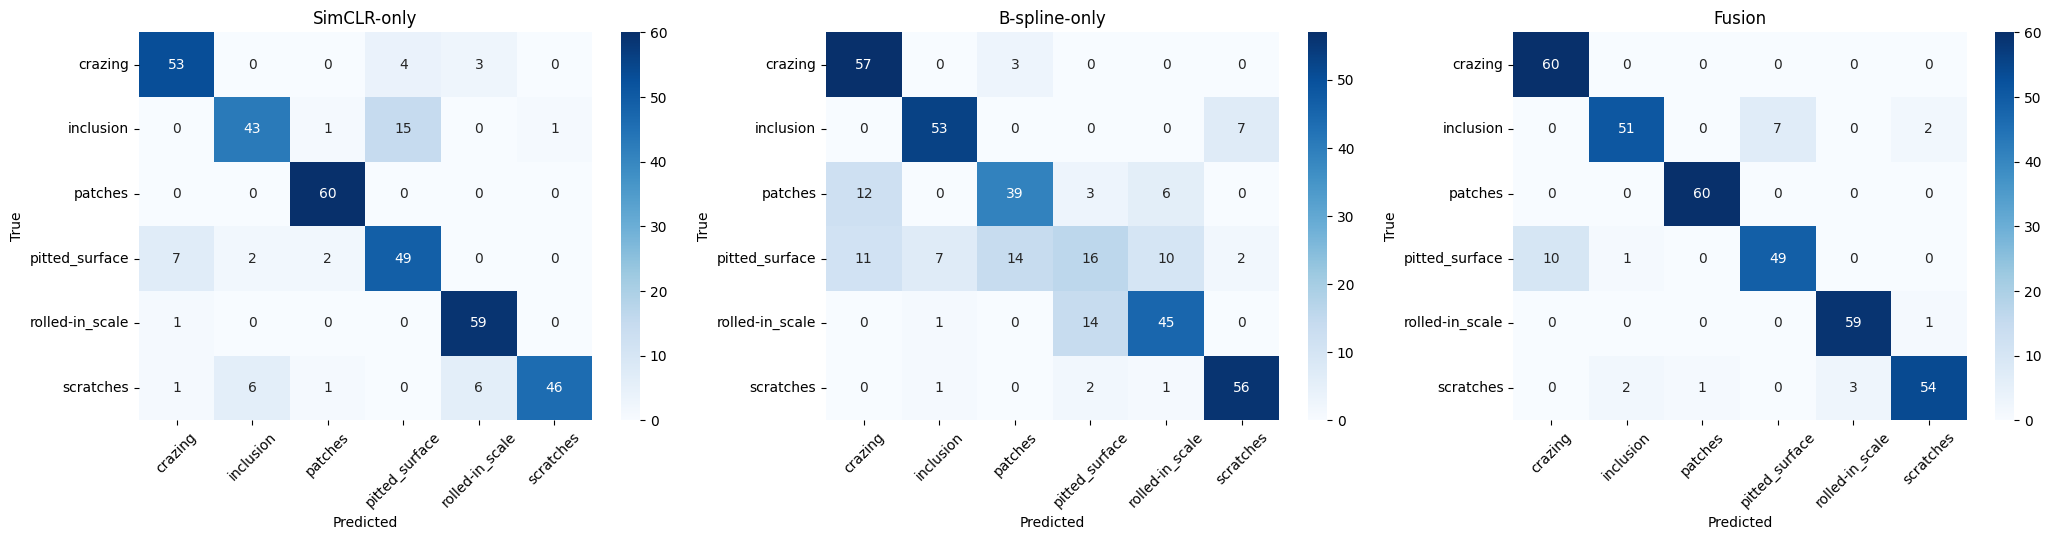

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
for ax, method_name in zip(axes, ['SimCLR-only', 'B-spline-only', 'Fusion']):
    cm = confusion_matrix(y_val, predictions[method_name], labels=CLASS_NAMES)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax
    )
    ax.set_title(method_name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.show()

## 11. Save metrics and per-image predictions

In [29]:
METRICS_FILE = OUTPUT_DIR / 'feature_fusion_comparison.csv'
PREDICTIONS_FILE = OUTPUT_DIR / 'feature_fusion_predictions.csv'

results_df.to_csv(METRICS_FILE, index=False)

pred_df = pd.DataFrame({
    'image_path': val_paths,
    'true_label': y_val,
    'pred_simclr': predictions['SimCLR-only'],
    'pred_bspline': predictions['B-spline-only'],
    'pred_fusion': predictions['Fusion']
})
pred_df.to_csv(PREDICTIONS_FILE, index=False)

print("Metrics saved:", METRICS_FILE)
print("Predictions saved:", PREDICTIONS_FILE)
display(results_df)

Metrics saved: /content/drive/MyDrive/METALYX/integrated_results/feature_fusion_comparison.csv
Predictions saved: /content/drive/MyDrive/METALYX/integrated_results/feature_fusion_predictions.csv


,method,train_samples,validation_samples,feature_dimensions,accuracy,macro_f1,weighted_f1
1,B-spline-only,1440,360,10,0.738889,0.721016,0.721016
2,Fusion,1440,360,522,0.925000,0.924111,0.924111
0,SimCLR-only,1440,360,512,0.861111,0.859780,0.859780


## 12. Interpretation and reporting checklist

- Compare the three rows in `feature_fusion_comparison.csv`. Fusion helps only if it improves the relevant metric under this same split and classifier protocol.
- Report accuracy **and** macro-F1; the latter gives equal weight to each defect class.
- Record the checkpoint path, its training provenance, preprocessing, seed, classifier parameters, and exact split.
- Confirm that the checkpoint was trained without using the official validation images. If those images were used in pretraining or repeated model selection, do not describe this as an untouched evaluation set.
- The ImageNet normalization in Section 6 must match the preprocessing expected by the saved encoder. Check the SimCLR training notebook before claiming strict reproducibility.
- This notebook uses the **encoder** output (512 dimensions), not the 128-dimensional projection-head output.
- If loading fails or reports missing encoder weights, stop and fix checkpoint key mapping. Do not treat a partially loaded random encoder as a valid SimCLR result.